Vision chat models listed:
  nvidia/nemotron-3.5-super-vl-120b-a12b


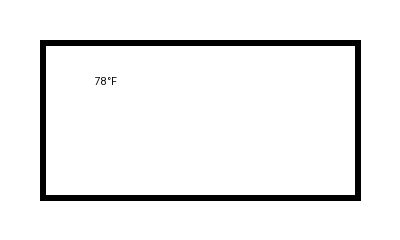

OK   nvidia/nemotron-3.5-super-vl-120b-a12b: '78°F'  (6.9s)  correct=True


In [2]:
import os, io, time, base64, requests
from google.colab import userdata
from PIL import Image, ImageDraw, ImageFont

KEY = userdata.get("NVIDIA_API_KEY")
H = {"Authorization": f"Bearer {KEY}", "Accept": "application/json"}

ids = [m["id"] for m in requests.get("https://integrate.api.nvidia.com/v1/models", headers=H, timeout=60).json()["data"]]
vision = sorted(i for i in ids
                if ("vision" in i.lower() or "-vl" in i.lower())
                and "embed" not in i.lower() and "retriever" not in i.lower())
print("Vision chat models listed:", *vision, sep="\n  ")

img = Image.new("RGB", (400, 240), "white")
d = ImageDraw.Draw(img)
d.rectangle([40, 40, 360, 200], outline="black", width=6)
try:
    font = ImageFont.truetype("/usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf", 80)
except Exception:
    font = ImageFont.load_default()
d.text((95, 75), "78°F", fill="black", font=font)
buf = io.BytesIO(); img.save(buf, format="PNG")
b64 = base64.b64encode(buf.getvalue()).decode()
display(img)

QUESTION = "What temperature does this thermostat display show? Reply with only the number and unit."

def try_model(model_id):
    start = time.time()
    body = {"model": model_id, "max_tokens": 1024, "temperature": 0.2,
            "chat_template_kwargs": {"enable_thinking": False, "thinking": False},
            "messages": [{"role": "user", "content": [
                {"type": "text", "text": QUESTION},
                {"type": "image_url", "image_url": {"url": f"data:image/png;base64,{b64}"}}]}]}
    try:
        r = requests.post("https://integrate.api.nvidia.com/v1/chat/completions", headers=H, json=body, timeout=120)
        if r.status_code == 400:  # model doesn't accept the thinking switch; retry without it
            body.pop("chat_template_kwargs")
            r = requests.post("https://integrate.api.nvidia.com/v1/chat/completions", headers=H, json=body, timeout=120)
        r.encoding = "utf-8"
        secs = round(time.time() - start, 1)
        if r.status_code != 200:
            print(f"FAIL {model_id}: HTTP {r.status_code} {r.text[:150]}  ({secs}s)")
            return
        msg = r.json()["choices"][0]["message"]
        answer = (msg.get("content") or msg.get("reasoning_content") or msg.get("reasoning") or "").strip()
        print(f"OK   {model_id}: {answer[-120:]!r}  ({secs}s)  correct={'78' in answer}")
    except Exception as e:
        print(f"FAIL {model_id}: {type(e).__name__}: {e}  ({round(time.time() - start, 1)}s)")

for m in vision:
    try_model(m)